# 02 · Manifold — principal-curve trajectory (whole malignant manifold)

Wu 2020's AML manifold is a single continuous cloud. We score the three embryonic modules, falsify a branch with a PPT **tree**, and — finding no co-expression hub or opposing arms — commit to a fold-free principal **curve** rooted at the Gast/pSom-high developmental origin. Continuity is certified off an **independent** diffusion embedding.

In [1]:
import os, sys, glob, io, contextlib
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
import scipy.sparse as sp
from scipy.sparse.csgraph import shortest_path
from numpy.linalg import svd
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*4))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_feat = os.path.join(pth_data, 'features', 'biomart')
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

### Load processed manifold and score developmental modules
Scores kept on the original joint embedding; graph-smoothed copies (`*_sm`) are used only for geography/correlation reads.

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
print('whole malignant manifold:', adata.shape[0], 'cells on the joint embedding')
xy = adata.obsm['X_umap']; cc = xy - xy.mean(0); u,s,vt = svd(cc, full_matrices=False)
print(f'UMAP aspect ratio (major/minor std): {s[0]/s[1]:.2f}')

# score the three embryonic modules with the union control pool (read hsapiens col, drop dupes)
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
label = {'GSE162534':'Gast','GSE229103':'pSom','rRNAModifications':'Crest'}
for src,lab in label.items():
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=lab, ctrl_as_ref=False, gene_pool=g_ref, random_state=1234)
    print(f'{lab}: {g.size}/{feat[src].size} genes present')
print('global module means: Gast %.4f  pSom %.4f  Crest %.4f'
      % (adata.obs.Gast.mean(), adata.obs.pSom.mean(), adata.obs.Crest.mean()))
# graph-smooth scores (knn averaging) for geography/correlation reads; raw kept for deliverables
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
for j,lab in enumerate(['Gast','pSom','Crest']): adata.obs[lab+'_sm'] = S[:,j]

whole malignant manifold: 96881 cells on the joint embedding
UMAP aspect ratio (major/minor std): 1.36
Gast: 41/81 genes present
pSom: 47/98 genes present
Crest: 72/104 genes present
global module means: Gast 0.0019  pSom 0.0066  Crest -0.0042


### Scope decision — whole manifold vs single lobe (data-driven)
Confirm the developmental axis is not confined to, or confounded by, a proliferation lobe.

In [4]:
# Scope decision (data-driven): is the developmental axis confined to one lobe, or does it span
# the whole manifold? Since 01 found a single low-cycling compartment, the whole manifold is the
# trajectory object; we confirm the developmental poles are not a proliferation artefact.
print('smoothed spatial correlations on the whole manifold:')
for a,b in [('Gast_sm','pSom_sm'),('Crest_sm','Gast_sm'),('Crest_sm','pSom_sm')]:
    r = np.corrcoef(adata.obs[a], adata.obs[b])[0,1]; print(f'  {a} vs {b}: r = {r:+.2f}')
print('\nper-compartment smoothed developmental means:')
print(adata.obs.groupby('compartment', observed=True)[['Gast_sm','pSom_sm','Crest_sm']].mean().round(4).to_string())
for pole,key in [('Crest-high (terminus)','Crest_sm'),('pSom-high (root)','pSom_sm'),('Gast-high','Gast_sm')]:
    hi = adata.obs[key] >= adata.obs[key].quantile(0.9)
    print(f'{pole} decile across compartments:', adata.obs.loc[hi.values,'compartment'].value_counts(normalize=True).round(2).to_dict())
print('-> one low-cycling compartment carries the whole developmental axis -> keep whole manifold (no scoping).')
sub = adata

smoothed spatial correlations on the whole manifold:
  Gast_sm vs pSom_sm: r = -0.68
  Crest_sm vs Gast_sm: r = -0.67
  Crest_sm vs pSom_sm: r = +0.11

per-compartment smoothed developmental means:
             Gast_sm  pSom_sm  Crest_sm
compartment                            
Low-cycling   0.0029   0.0063   -0.0047
Crest-high (terminus) decile across compartments: {'Low-cycling': 1.0}
pSom-high (root) decile across compartments: {'Low-cycling': 1.0}
Gast-high decile across compartments: {'Low-cycling': 1.0}
-> one low-cycling compartment carries the whole developmental axis -> keep whole manifold (no scoping).


### Falsification test — is there a branch? (PPT tree)
Fit a tree that *can* branch and read the biology at each node; geometric branches with identical signatures do not count.

In [5]:
# Falsification test — is there a branch? Fit a PPT tree (which CAN branch) and inspect the
# biology at each tip/fork. A genuine bifurcation needs a Gast/pSom co-expression hub diverging into
# a Gast-leaning and a pSom-leaning arm. If every tip carries the same signature means, the tree's
# branches are geometric, not biological -> a curve is the honest fit.
ad_t = sub.copy()
sig0 = 0.1*np.ptp(ad_t.obsm['X_umap'])
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.tree(ad_t, Nodes=20, use_rep='X_umap', method='ppt', ppt_lambda=100, ppt_sigma=sig0, seed=SEED, plot=False)
Bt = np.asarray(ad_t.uns['graph']['B']); degt = (Bt>0).sum(0)
tips_t = np.where(degt==1)[0]; forks_t = np.where(degt>=3)[0]
Dt = shortest_path(sp.csr_matrix((Bt>0).astype(int)), unweighted=True)
hard_t = np.asarray(ad_t.obsm['X_R']).argmax(1)
print(f'tree: {len(tips_t)} tips, {len(forks_t)} fork(s) -> inspect fork/tip biology:')
for grp,node in [('tip%d'%t,t) for t in tips_t] + [('fork%d'%f,f) for f in forks_t]:
    m = np.isin(hard_t, np.where(Dt[node]<=2)[0])
    print(f'  {grp}: n={int(m.sum()):5d} Gast={sub.obs["Gast_sm"][m].mean():+.4f} '
          f'pSom={sub.obs["pSom_sm"][m].mean():+.4f} Crest={sub.obs["Crest_sm"][m].mean():+.4f}')
print('all tips/fork carry near-identical Gast/pSom/Crest -> no co-expression hub, no opposing arms')
print('-> non-branching: fit a principal curve.')

tree: 3 tips, 1 fork(s) -> inspect fork/tip biology:
  tip10: n=11623 Gast=+0.0033 pSom=+0.0060 Crest=-0.0049
  tip13: n=28519 Gast=+0.0026 pSom=+0.0067 Crest=-0.0052
  tip15: n=30861 Gast=+0.0024 pSom=+0.0064 Crest=-0.0038
  fork0: n=15879 Gast=+0.0034 pSom=+0.0061 Crest=-0.0049
all tips/fork carry near-identical Gast/pSom/Crest -> no co-expression hub, no opposing arms
-> non-branching: fit a principal curve.


### Fit the principal curve (ElPiGraph)
A fold-free monotone backbone — the self-approach ratio must exceed 1.

In [6]:
# Fit the principal curve (ElPiGraph) and prove it is fold-free: the minimum euclidean distance
# between graph-distant nodes, over the median edge length, must exceed 1 (no self-approach / U-fold).
def fold_diag(ad):
    B = np.asarray(ad.uns['graph']['B']); F = ad.uns['graph']['F'].T
    G = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
    ii,jj = np.where(np.triu(B>0)); med_edge = np.median(np.sqrt(((F[ii]-F[jj])**2).sum(1)))
    dmin = np.inf
    for a in range(F.shape[0]):
        for b in range(a+1, F.shape[0]):
            if G[a,b] >= 3: dmin = min(dmin, np.sqrt(((F[a]-F[b])**2).sum()))
    tips = int(((B>0).sum(0)==1).sum()); forks = int(((B>0).sum(0)>=3).sum())
    return dmin/med_edge, tips, forks
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.curve(sub, Nodes=20, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
sa, tips, forks = fold_diag(sub)
print(f'curve: {tips} tips, {forks} forks | fold self-approach ratio = {sa:.2f} (>1 = fold-free)')
assert forks == 0 and sa > 1, "topology check failed"

curve: 2 tips, 0 forks | fold self-approach ratio = 2.90 (>1 = fold-free)


### Derive the root (data-driven)
The root is the curve tip where Gast+pSom is highest and Crest lowest — the developmental origin, never a proliferation state.

In [7]:
# Derive the root (data-driven): developmentally Gast/pSom is EARLY and Crest is LATE, so the root
# is the curve tip where Gast+pSom is highest and Crest lowest - never a proliferation state.
B = np.asarray(sub.uns['graph']['B']); tps = np.where((B>0).sum(0)==1)[0]
R = np.asarray(sub.obsm['X_R']); hard = R.argmax(1)
D = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
info = {}
for tp in tps:
    m = np.isin(hard, np.where(D[tp]<=3)[0])
    info[tp] = (sub.obs['Gast_sm'][m].mean(), sub.obs['pSom_sm'][m].mean(), sub.obs['Crest_sm'][m].mean())
    print(f'tip {tp}: Gast={info[tp][0]:+.4f} pSom={info[tp][1]:+.4f} Crest={info[tp][2]:+.4f}')
root = int(max(tps, key=lambda tp: info[tp][0]+info[tp][1]-info[tp][2]))
print('derived root = tip', root, '(Gast/pSom-high, Crest-low = developmental origin)')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.root(sub, root); scf.tl.pseudotime(sub, n_map=1, seed=SEED)
t = sub.obs['t'].values
sub.obs['cyc_score'] = pd.to_numeric(sub.obs['g1s_score'], errors='coerce').fillna(0).combine(
                       pd.to_numeric(sub.obs['g2m_score'], errors='coerce').fillna(0), max)
print('gradient along pseudotime (Spearman rho on smoothed):')
for s in ['Gast_sm','pSom_sm','Crest_sm','cyc_score']:
    rho,p = spearmanr(t, sub.obs[s]); print(f'  {s}: rho={rho:+.3f} p={p:.1e}')

tip 0: Gast=+0.0024 pSom=+0.0067 Crest=-0.0051
tip 2: Gast=+0.0023 pSom=+0.0064 Crest=-0.0037
derived root = tip 0 (Gast/pSom-high, Crest-low = developmental origin)
gradient along pseudotime (Spearman rho on smoothed):
  Gast_sm: rho=-0.055 p=1.4e-66
  pSom_sm: rho=-0.023 p=3.1e-13
  Crest_sm: rho=+0.431 p=0.0e+00
  cyc_score: rho=-0.066 p=3.6e-95


### Independent-embedding continuity check
Certify continuity with a diffusion-map metric not built from the UMAP under test.

In [8]:
# Independent-embedding continuity check: certify continuity with a metric NOT built from the UMAP
# being tested. A diffusion map is computed independently; a single continuous component projects the
# pseudotime onto one diffusion component with |corr| >= 0.8.
sc.tl.diffmap(sub)
r_dc1 = abs(np.corrcoef(t, sub.obsm['X_diffmap'][:,1])[0,1])
r_dc2 = abs(np.corrcoef(t, sub.obsm['X_diffmap'][:,2])[0,1])
print(f'|corr(pseudotime, DC1)| = {r_dc1:.2f} | DC2 = {r_dc2:.2f} (>=0.8 on a component = continuous)')
assert max(r_dc1, r_dc2) > 0.8, 'continuity check failed on independent embedding' 

|corr(pseudotime, DC1)| = 0.92 | DC2 = 0.02 (>=0.8 on a component = continuous)


### Reorient to house style (pseudotime left → right)

In [9]:
# Reorient to house style (pseudotime left -> right) using only raw UMAP coordinates (discrete
# sign/axis choice; no re-embedding of the linear compartment).
xy = sub.obsm['X_umap'].copy(); t = sub.obs['t'].values
if abs(np.corrcoef(xy[:,1], t)[0,1]) > abs(np.corrcoef(xy[:,0], t)[0,1]):
    xyr = np.column_stack([xy[:,1], xy[:,0]])   # pseudotime aligns with y -> swap to x
else:
    xyr = np.column_stack([xy[:,0], xy[:,1]])
r = float(np.corrcoef(xyr[:,0], t)[0,1])
if r < 0: xyr[:,0] = -xyr[:,0]; r = -r
assert r > 0, f'pseudotime not left->right (corr={r:+.2f})'
sub.obsm['X_umap_lin'] = xyr
print(f'orientation: corr(x_lin, pseudotime) = {r:+.2f} (root at left)')

orientation: corr(x_lin, pseudotime) = +0.97 (root at left)


### Save manifold + trajectory figure (deliverable)

saved manifold.h5ad + manifold.pdf


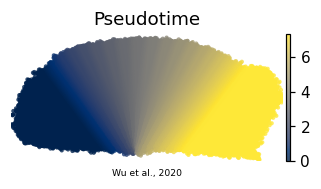

In [10]:
# sanitize non-serializable ElPiGraph uns entry (node positions kept; graph lives in uns['graph'])
sub.uns['epg'] = {'NodePositions': np.asarray(sub.uns['epg']['NodePositions'])}
sub.uns['gate'] = {**adata.uns.get('gate1',{}), 'root_tip':int(root), 'geometry':'curve',
                   'dc_corr':float(max(r_dc1,r_dc2)), 'fold_ratio':float(sa)}
sub.write(os.path.join(pth_out, 'manifold.h5ad'))
xl = sub.obsm['X_umap_lin']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
plot = sub.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='t', cmap='cividis', size=30, alpha=.8, colorbar_loc='right',
           frameon=False, show=False, ax=ax, title='Pseudotime')
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.text(.5,-.12,'Wu et al., 2020', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'manifold.pdf'), bbox_inches='tight')
print('saved manifold.h5ad + manifold.pdf')